# Walmart Weekly Sales Forecasting

**Objective:** memprediksi `Weekly_Sales` untuk setiap kombinasi Store x Department x Date menggunakan pendekatan CRISP-DM, feature engineering time-series, dan perbandingan beberapa algoritma machine learning.

Business use case: inventory planning, stock allocation, staffing/resource planning, dan promotional planning. Notebook ini menyajikan prediksi dan feature importance sebagai kontribusi terhadap model — bukan hubungan sebab-akibat (causal) terhadap penjualan.

## 1. Business Understanding

**Business problem:** Walmart perlu memperkirakan `Weekly_Sales` per Store dan Department untuk mendukung perencanaan inventori, alokasi stok, staffing, dan promosi.

**Data mining objective:** membangun dan membandingkan beberapa model regresi untuk memprediksi `Weekly_Sales` pada level Store x Department x Date, lalu menghasilkan forecast untuk periode yang belum terjadi (`test.csv`).

## 2. Data Understanding

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

DATA_DIR = "data"
RANDOM_STATE = 42

In [ ]:
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
features = pd.read_csv(f"{DATA_DIR}/features.csv")
stores = pd.read_csv(f"{DATA_DIR}/stores.csv")
for df in (train, test, features):
    df["Date"] = pd.to_datetime(df["Date"])

print(f"train: {train.shape} | test: {test.shape} | features: {features.shape} | stores: {stores.shape}")
unique_dates = train["Date"].drop_duplicates().sort_values()
weekly_interval = unique_dates.diff().dropna().mode().iloc[0].days
print(f"Frekuensi data: mingguan (interval antar tanggal = {weekly_interval} hari, dihitung dari unique dates)")
print(f"Train period : {train['Date'].min().date()} -> {train['Date'].max().date()}")
print(f"Test period  : {test['Date'].min().date()} -> {test['Date'].max().date()}")
print(f"Unique Store : {train['Store'].nunique()} | Unique Dept: {train['Dept'].nunique()}")
print(f"Grain        : Store x Dept x Date")

train: (421570, 5) | test: (115064, 4) | features: (8190, 12) | stores: (45, 3)
Frekuensi data: mingguan (interval antar tanggal = 7 hari, dihitung dari unique dates)
Train period : 2010-02-05 -> 2012-10-26
Test period  : 2012-11-02 -> 2013-07-26
Unique Store : 45 | Unique Dept: 81
Grain        : Store x Dept x Date


In [ ]:
print("=== Missing values ===")
for name, df in [("train", train), ("test", test), ("features", features), ("stores", stores)]:
    missing = df.isna().sum()
    print(f"{name}: {dict(missing[missing > 0]) if missing.sum() else 'tidak ada'}")

print("\n=== Duplicate Store-Dept-Date di train ===", train.duplicated(subset=["Store", "Dept", "Date"]).sum())
print("=== Weekly_Sales describe ===")
print(train["Weekly_Sales"].describe())
print(f"\nNegative Weekly_Sales: {(train['Weekly_Sales'] < 0).sum()} baris ({(train['Weekly_Sales'] < 0).mean()*100:.2f}%)")

=== Missing values ===
train: tidak ada
test: tidak ada
features: {'MarkDown1': np.int64(4158), 'MarkDown2': np.int64(5269), 'MarkDown3': np.int64(4577), 'MarkDown4': np.int64(4726), 'MarkDown5': np.int64(4140), 'CPI': np.int64(585), 'Unemployment': np.int64(585)}
stores: tidak ada

=== Duplicate Store-Dept-Date di train === 0
=== Weekly_Sales describe ===
count    421570.000000
mean      15981.258123
std       22711.183519
min       -4988.940000
25%        2079.650000
50%        7612.030000
75%       20205.852500
max      693099.360000
Name: Weekly_Sales, dtype: float64

Negative Weekly_Sales: 1285 baris (0.30%)


## 3. Data Preparation

### 3.1 Data Integration

In [ ]:
features_clean = features.drop(columns=["IsHoliday"])  # sudah ada di train/test, hindari kolom duplikat
train_m = train.merge(stores, on="Store", how="left").merge(features_clean, on=["Store", "Date"], how="left")
test_m = test.merge(stores, on="Store", how="left").merge(features_clean, on=["Store", "Date"], how="left")

for df in (train_m, test_m):
    df["IsHoliday"] = df["IsHoliday"].astype(int)

print(train_m.shape, test_m.shape)

(421570, 16) (115064, 15)


### 3.2 Missing Value Handling

In [ ]:
markdown_cols = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]
for df in (train_m, test_m):
    df[markdown_cols] = df[markdown_cols].fillna(0)

econ = features[["Store", "Date", "CPI", "Unemployment"]].sort_values(["Store", "Date"]).copy()
econ[["CPI", "Unemployment"]] = econ.groupby("Store")[["CPI", "Unemployment"]].ffill()  # hanya ffill, tidak bfill

train_m = train_m.drop(columns=["CPI", "Unemployment"]).merge(econ, on=["Store", "Date"], how="left")
test_m = test_m.drop(columns=["CPI", "Unemployment"]).merge(econ, on=["Store", "Date"], how="left")

print("Missing values setelah ffill:")
print("train:", dict(train_m[["CPI", "Unemployment"]].isna().sum()))
print("test :", dict(test_m[["CPI", "Unemployment"]].isna().sum()))

Missing values setelah ffill:
train: {'CPI': np.int64(0), 'Unemployment': np.int64(0)}
test : {'CPI': np.int64(0), 'Unemployment': np.int64(0)}


### 3.3 Outlier Analysis

Outlier rows: 35521 (8.43%)
Proporsi holiday week di antara outlier : 7.4%
Proporsi holiday week di seluruh data    : 7.0%


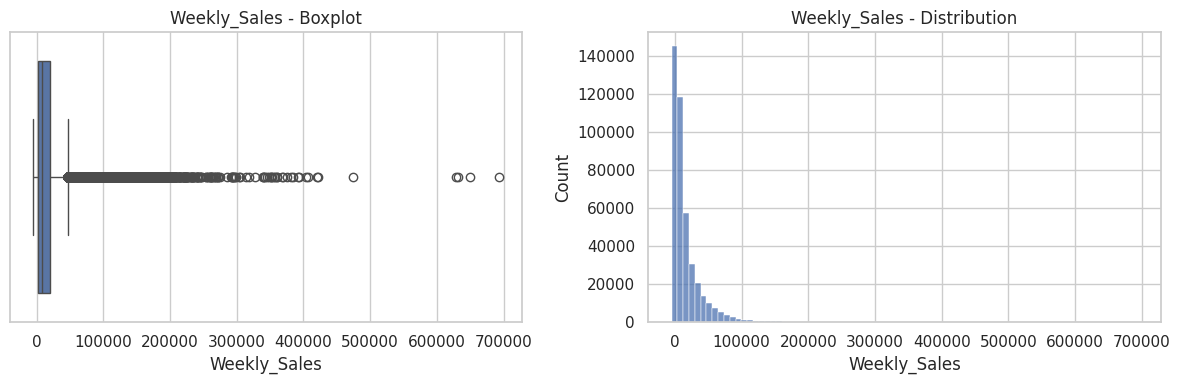

In [ ]:
q1, q3 = train_m["Weekly_Sales"].quantile([0.25, 0.75])
iqr = q3 - q1
outlier_mask = (train_m["Weekly_Sales"] < q1 - 1.5 * iqr) | (train_m["Weekly_Sales"] > q3 + 1.5 * iqr)
print(f"Outlier rows: {outlier_mask.sum()} ({outlier_mask.mean()*100:.2f}%)")
print(f"Proporsi holiday week di antara outlier : {train_m.loc[outlier_mask, 'IsHoliday'].mean()*100:.1f}%")
print(f"Proporsi holiday week di seluruh data    : {train_m['IsHoliday'].mean()*100:.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=train_m["Weekly_Sales"], ax=ax[0]); ax[0].set_title("Weekly_Sales - Boxplot")
sns.histplot(train_m["Weekly_Sales"], bins=80, ax=ax[1]); ax[1].set_title("Weekly_Sales - Distribution")
plt.tight_layout(); plt.show()

## 4. Exploratory Data Analysis

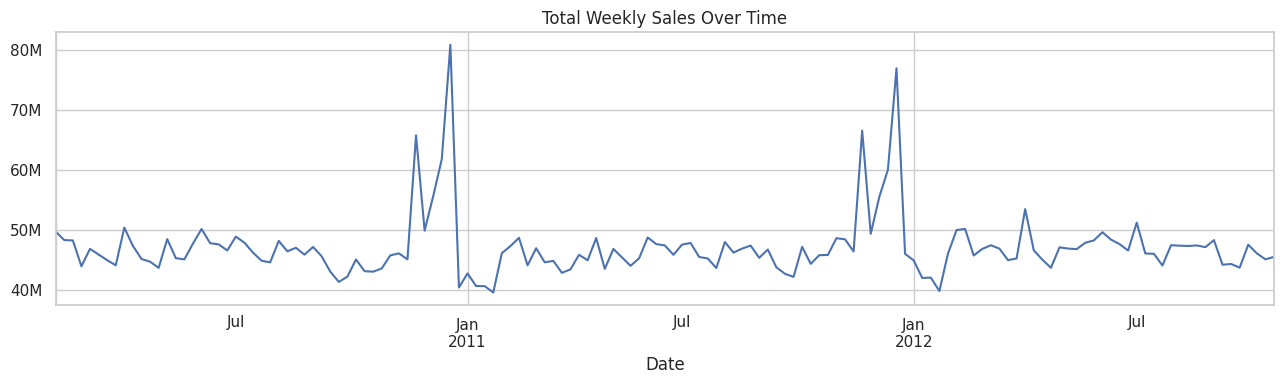

In [ ]:
weekly_total = train_m.groupby("Date")["Weekly_Sales"].sum()
fig, ax = plt.subplots(figsize=(13, 4))
weekly_total.plot(ax=ax)
ax.set_title("Total Weekly Sales Over Time")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.0f}M"))
plt.tight_layout(); plt.show()

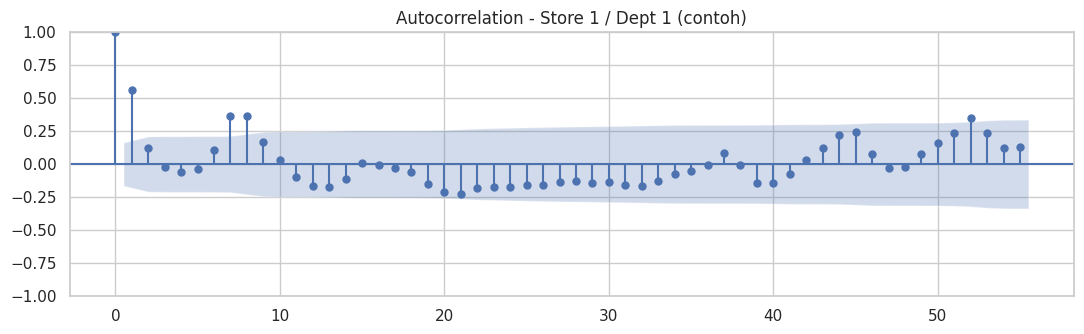

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

sample_series = train_m[(train_m["Store"] == 1) & (train_m["Dept"] == 1)].sort_values("Date")["Weekly_Sales"]
fig, ax = plt.subplots(figsize=(11, 3.5))
plot_acf(sample_series, lags=55, ax=ax)
ax.set_title("Autocorrelation - Store 1 / Dept 1 (contoh)")
plt.tight_layout(); plt.show()

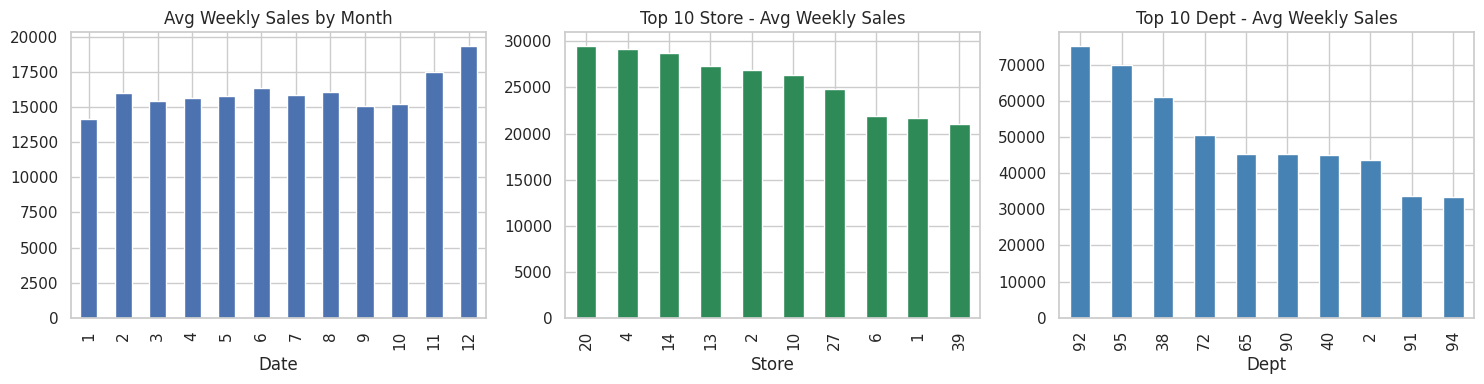

Rata-rata Weekly Sales per Store Type:
Type
A    20099.568043
B    12237.075977
C     9519.532538
Name: Weekly_Sales, dtype: float64


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
train_m.groupby(train_m["Date"].dt.month)["Weekly_Sales"].mean().plot(kind="bar", ax=ax[0], color=sns.color_palette()[0])
ax[0].set_title("Avg Weekly Sales by Month")
train_m.groupby("Store")["Weekly_Sales"].mean().sort_values(ascending=False).head(10).plot(kind="bar", ax=ax[1], color="seagreen")
ax[1].set_title("Top 10 Store - Avg Weekly Sales")
train_m.groupby("Dept")["Weekly_Sales"].mean().sort_values(ascending=False).head(10).plot(kind="bar", ax=ax[2], color="steelblue")
ax[2].set_title("Top 10 Dept - Avg Weekly Sales")
plt.tight_layout(); plt.show()

print("Rata-rata Weekly Sales per Store Type:")
print(train_m.groupby("Type")["Weekly_Sales"].mean().sort_values(ascending=False))

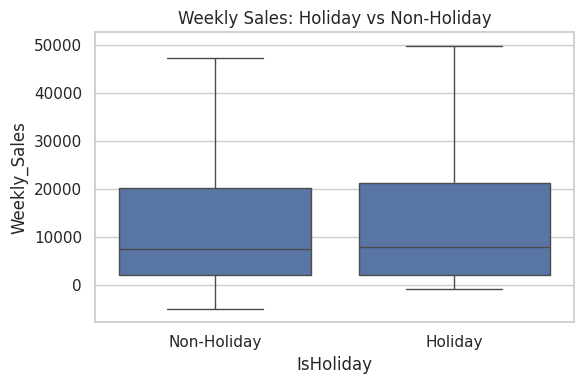

Rata-rata Weekly Sales holiday week 7.1% lebih tinggi dibanding non-holiday week.
Rata-rata Weekly Sales saat markdown aktif: 16,177 vs tanpa markdown: 15,872


In [ ]:
holiday_stats = train_m.groupby("IsHoliday")["Weekly_Sales"].mean()
lift = (holiday_stats[1] / holiday_stats[0] - 1) * 100

markdown_active = train_m[markdown_cols].sum(axis=1) > 0
md_stats = train_m.groupby(markdown_active)["Weekly_Sales"].mean()

fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=train_m, x="IsHoliday", y="Weekly_Sales", showfliers=False, ax=ax)
ax.set_xticklabels(["Non-Holiday", "Holiday"]); ax.set_title("Weekly Sales: Holiday vs Non-Holiday")
plt.tight_layout(); plt.show()

print(f"Rata-rata Weekly Sales holiday week {lift:.1f}% lebih tinggi dibanding non-holiday week.")
print(f"Rata-rata Weekly Sales saat markdown aktif: {md_stats[True]:,.0f} vs tanpa markdown: {md_stats[False]:,.0f}")

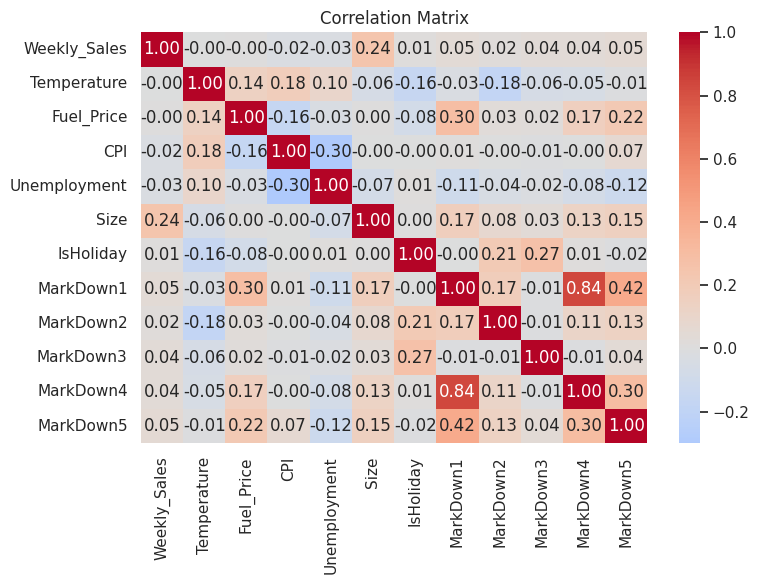

In [ ]:
numeric_cols = ["Weekly_Sales", "Temperature", "Fuel_Price", "CPI", "Unemployment", "Size", "IsHoliday"] + markdown_cols
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(train_m[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Matrix")
plt.tight_layout(); plt.show()

## 5. Feature Engineering

Fitur kalender: `Year`, `Month`, `WeekOfYear`, `Quarter`, `DayOfWeek`.

Fitur lag (per Store + Dept): `Sales_Lag_1/2/4/8/12/52`.

Fitur rolling (per Store + Dept): `Rolling_Mean_4/8/12`, `Rolling_Std_4/12`.

In [ ]:
def add_calendar_features(df):
    df = df.copy()
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)
    df["Quarter"] = df["Date"].dt.quarter
    df["DayOfWeek"] = df["Date"].dt.dayofweek
    return df

train_m = add_calendar_features(train_m)
test_m = add_calendar_features(test_m)

LAGS = [1, 2, 4, 8, 12, 52]
ROLLS = [4, 8, 12]

def build_lag_rolling_features(history, target, lags=LAGS, rolls=ROLLS):
    # Fungsi ini hanya dipakai untuk data historis (train), di mana setiap baris target
    h = history.sort_values(["Store", "Dept", "Date"]).copy()
    grouped = h.groupby(["Store", "Dept"])["Weekly_Sales"]
    for lag in lags:
        h[f"Sales_Lag_{lag}"] = grouped.shift(lag)
    shifted = grouped.shift(1)  # rolling dihitung setelah shift agar hanya memakai data sebelum periode target
    keys = [h["Store"], h["Dept"]]
    for w in rolls:
        h[f"Rolling_Mean_{w}"] = shifted.groupby(keys).transform(lambda s: s.rolling(w).mean())
        if w in (4, 12):
            h[f"Rolling_Std_{w}"] = shifted.groupby(keys).transform(lambda s: s.rolling(w).std())
    feat_cols = [c for c in h.columns if c.startswith("Sales_Lag_") or c.startswith("Rolling_")]
    return target.merge(h[["Store", "Dept", "Date"] + feat_cols], on=["Store", "Dept", "Date"], how="left"), feat_cols

train_feat, LAG_COLS = build_lag_rolling_features(train_m[["Store", "Dept", "Date", "Weekly_Sales"]], train_m)
train_model = train_feat.dropna(subset=LAG_COLS).reset_index(drop=True)
print(f"Rows sebelum dropna: {len(train_feat)} | sesudah: {len(train_model)} (baris awal tiap Store-Dept belum punya 52 minggu histori)")

Rows sebelum dropna: 421570 | sesudah: 261083 (baris awal tiap Store-Dept belum punya 52 minggu histori)


In [ ]:
date_gaps = train_m.sort_values(["Store", "Dept", "Date"]).groupby(["Store", "Dept"])["Date"].diff().dt.days
irregular = (date_gaps.dropna() != 7)
print(f"Gap tanggal != 7 hari: {irregular.sum():,} / {date_gaps.dropna().shape[0]:,} ({irregular.mean()*100:.2f}%)")

Gap tanggal != 7 hari: 5,447 / 418,239 (1.30%)


## 6. Train Validation Holdout Split

In [ ]:
TRAIN_END = "2012-02-29"
VAL_END = "2012-06-30"

fit_set = train_model[train_model["Date"] <= TRAIN_END].reset_index(drop=True)
val_set = train_model[(train_model["Date"] > TRAIN_END) & (train_model["Date"] <= VAL_END)].reset_index(drop=True)
holdout_set = train_model[train_model["Date"] > VAL_END].reset_index(drop=True)

assert fit_set["Date"].max() < val_set["Date"].min()
assert val_set["Date"].max() < holdout_set["Date"].min()

for name, s in [("fit", fit_set), ("validation", val_set), ("holdout", holdout_set)]:
    print(f"{name:<11}: {s.shape}  {s['Date'].min().date()} -> {s['Date'].max().date()}")

FEATURE_COLS = (["Store", "Dept", "IsHoliday", "Temperature", "Fuel_Price"] + markdown_cols +
                ["CPI", "Unemployment", "Size", "Type", "Year", "Month", "WeekOfYear", "Quarter", "DayOfWeek"] + LAG_COLS)
CAT_COLS = ["Type"]
NUM_COLS = [c for c in FEATURE_COLS if c not in CAT_COLS]

def xy(df):
    return df[FEATURE_COLS], df["Weekly_Sales"]

X_fit, y_fit = xy(fit_set)
X_val, y_val = xy(val_set)
X_hold, y_hold = xy(holdout_set)

TYPE_MAPPING = {"A": 0, "B": 1, "C": 2}

def to_tree_input(df):
    out = df.copy()
    out["Type"] = out["Type"].map(TYPE_MAPPING)
    if out["Type"].isna().any():
        raise ValueError("Ditemukan kategori Type di luar TYPE_MAPPING - encoding tidak konsisten")
    return out

Xt_fit, Xt_val, Xt_hold = to_tree_input(X_fit), to_tree_input(X_val), to_tree_input(X_hold)

fit        : (159474, 32)  2011-02-04 -> 2012-02-24
validation : (52192, 32)  2012-03-02 -> 2012-06-29
holdout    : (49417, 32)  2012-07-06 -> 2012-10-26


## 7. Baseline Modeling

Linear Regression sebagai baseline linear sebelum model nonlinear.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    wape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true))
    mape = np.nanmean(np.abs((y_true - y_pred) / np.where(y_true == 0, np.nan, y_true))) * 100  # supplementary, baris actual=0 diabaikan (bukan bikin seluruh rata-rata NaN)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "WAPE": wape,
        "R2": r2_score(y_true, y_pred),
        "MAPE": mape,
    }

preprocess = ColumnTransformer([("num", StandardScaler(), NUM_COLS), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)])
lr_model = Pipeline([("prep", preprocess), ("model", LinearRegression())]).fit(X_fit, y_fit)

val_results = {"Linear Regression": regression_metrics(y_val, lr_model.predict(X_val))}
val_results["Linear Regression"]

{'MAE': 1658.9671967822367,
 'RMSE': 3615.719284583031,
 'WAPE': np.float64(0.10190522775737168),
 'R2': 0.9735499456167007,
 'MAPE': np.float64(3405.625132519357)}

## 8. Modeling

In [ ]:
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
import lightgbm as lgb

rf_base = RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_leaf=8, max_samples=0.4, n_jobs=-1, random_state=RANDOM_STATE).fit(Xt_fit, y_fit)
xgb_base = xgb.XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE).fit(Xt_fit, y_fit)
lgb_base = lgb.LGBMRegressor(n_estimators=300, max_depth=6, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=RANDOM_STATE, verbose=-1).fit(Xt_fit, y_fit)

for name, model in [("Random Forest", rf_base), ("XGBoost", xgb_base), ("LightGBM", lgb_base)]:
    val_results[name] = regression_metrics(y_val, model.predict(Xt_val))

pd.DataFrame(val_results).T[["MAE", "RMSE", "WAPE", "R2", "MAPE"]].round(2)

,MAE,RMSE,WAPE,R2,MAPE
Linear Regression,1658.97,3615.72,0.10,0.97,3405.63
Random Forest,1420.16,3291.96,0.09,0.98,482.58
XGBoost,1456.41,3445.90,0.09,0.98,1065.46
LightGBM,1499.72,3599.76,0.09,0.97,983.09


## 9. Hyperparameter Tuning

In [ ]:
def make_expanding_date_folds(dates, n_splits=3):
    blocks = np.array_split(np.unique(dates), n_splits + 1)
    folds, train_cutoff = [], blocks[0][-1]
    for block in blocks[1:]:
        train_idx = np.where(dates <= train_cutoff)[0]
        val_idx = np.where((dates >= block[0]) & (dates <= block[-1]))[0]
        folds.append((train_idx, val_idx))
        train_cutoff = block[-1]
    return folds

fit_sorted = fit_set.sort_values("Date").reset_index(drop=True)
Xt_fit_sorted = to_tree_input(fit_sorted[FEATURE_COLS])
y_fit_sorted = fit_sorted["Weekly_Sales"]
date_values = fit_sorted["Date"].values

cv_folds = make_expanding_date_folds(date_values, n_splits=3)
for i, (tr, va) in enumerate(cv_folds, 1):
    print(f"Fold {i}: train <= {fit_sorted['Date'].iloc[tr].max().date()} ({len(tr)} rows) | "
          f"validate {fit_sorted['Date'].iloc[va].min().date()} -> {fit_sorted['Date'].iloc[va].max().date()} ({len(va)} rows)")

Fold 1: train <= 2011-05-06 (39032 rows) | validate 2011-05-13 -> 2011-08-12 (39737 rows)
Fold 2: train <= 2011-08-12 (78769 rows) | validate 2011-08-19 -> 2011-11-18 (40181 rows)
Fold 3: train <= 2011-11-18 (118950 rows) | validate 2011-11-25 -> 2012-02-24 (40524 rows)


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

rf_space = {"n_estimators": [60, 100, 150], "max_depth": [8, 10, 12], "min_samples_leaf": [5, 8, 10], "max_samples": [0.3, 0.4, 0.5]}
rf_search = RandomizedSearchCV(RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE), rf_space, n_iter=4,
                                cv=cv_folds, scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=1)
rf_search.fit(Xt_fit_sorted, y_fit_sorted)
print("Best Random Forest params:", rf_search.best_params_)

Best Random Forest params: {'n_estimators': 60, 'min_samples_leaf': 8, 'max_samples': 0.3, 'max_depth': 10}


In [ ]:
xgb_space = {"n_estimators": [200, 300, 400], "max_depth": [5, 6, 7, 8], "learning_rate": [0.03, 0.05, 0.08, 0.1],
             "subsample": [0.7, 0.8, 0.9], "colsample_bytree": [0.7, 0.8, 0.9], "min_child_weight": [1, 3, 5]}
xgb_search = RandomizedSearchCV(xgb.XGBRegressor(tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE), xgb_space, n_iter=6,
                                 cv=cv_folds, scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=1)
xgb_search.fit(Xt_fit_sorted, y_fit_sorted)
print("Best XGBoost params:", xgb_search.best_params_)

Best XGBoost params: {'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 7, 'learning_rate': 0.05, 'colsample_bytree': 0.9}


In [ ]:
lgb_space = {"n_estimators": [200, 300, 400], "max_depth": [5, 6, 7, 8], "learning_rate": [0.03, 0.05, 0.08, 0.1],
             "num_leaves": [31, 50, 70], "subsample": [0.7, 0.8, 0.9], "colsample_bytree": [0.7, 0.8, 0.9], "min_child_samples": [10, 20, 30]}
lgb_search = RandomizedSearchCV(lgb.LGBMRegressor(n_jobs=-1, random_state=RANDOM_STATE, verbose=-1), lgb_space, n_iter=5,
                                 cv=cv_folds, scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=1)
lgb_search.fit(Xt_fit_sorted, y_fit_sorted)
print("Best LightGBM params:", lgb_search.best_params_)

Best LightGBM params: {'subsample': 0.7, 'num_leaves': 70, 'n_estimators': 300, 'min_child_samples': 10, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.9}


In [ ]:
rf_tuned = RandomForestRegressor(**rf_search.best_params_, n_jobs=-1, random_state=RANDOM_STATE).fit(Xt_fit, y_fit)
xgb_tuned = xgb.XGBRegressor(**xgb_search.best_params_, tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE).fit(Xt_fit, y_fit)
lgb_tuned = lgb.LGBMRegressor(**lgb_search.best_params_, n_jobs=-1, random_state=RANDOM_STATE, verbose=-1).fit(Xt_fit, y_fit)
print("Tuned models fitted.")

Tuned models fitted.


## 10. Model Evaluation

Metrik utama: **MAE**. Metrik pendukung: RMSE, WAPE, R², MAPE

In [ ]:
candidates = {
    "Linear Regression": lr_model,
    "Random Forest (tuned)": rf_tuned,
    "XGBoost (tuned)": xgb_tuned,
    "LightGBM (tuned)": lgb_tuned,
}

def predict_with(model, X, Xt):
    return model.predict(X) if model is lr_model else model.predict(Xt)

val_table = pd.DataFrame({name: regression_metrics(y_val, predict_with(m, X_val, Xt_val)) for name, m in candidates.items()}).T
val_table = val_table[["MAE", "RMSE", "WAPE", "R2", "MAPE"]].sort_values("MAE")
print("=== Validation ===")
val_table.round(3)

=== Validation ===


,MAE,RMSE,WAPE,R2,MAPE
XGBoost (tuned),1417.485,3272.241,0.087,0.978,863.395
Random Forest (tuned),1421.246,3298.109,0.087,0.978,517.915
LightGBM (tuned),1449.092,3427.490,0.089,0.976,961.910
Linear Regression,1658.967,3615.719,0.102,0.974,3405.625


In [ ]:
hold_table = pd.DataFrame({name: regression_metrics(y_hold, predict_with(m, X_hold, Xt_hold)) for name, m in candidates.items()}).T
hold_table = hold_table[["MAE", "RMSE", "WAPE", "R2", "MAPE"]].sort_values("MAE")
print("=== Holdout ===")
hold_table.round(3)

=== Holdout ===


,MAE,RMSE,WAPE,R2,MAPE
Random Forest (tuned),1248.214,2611.520,0.078,0.986,97.708
XGBoost (tuned),1272.119,2672.880,0.080,0.985,184.506
LightGBM (tuned),1292.611,2718.412,0.081,0.985,132.275
Linear Regression,1656.131,3007.272,0.104,0.981,790.595


## 11. Final Model Selection

In [ ]:
best_name = val_table.index[0]
best_model = candidates[best_name]
is_tree_model = best_name != "Linear Regression"

print(f"Model {best_name} menghasilkan MAE terendah pada validation set.")
print("\n=== Validation (dasar seleksi) ===")
print(val_table.loc[best_name])
print("\n=== Holdout (evaluasi akhir, blind) ===")
print(hold_table.loc[best_name])

Model XGBoost (tuned) menghasilkan MAE terendah pada validation set.

=== Validation (dasar seleksi) ===
MAE     1417.485038
RMSE    3272.240553
WAPE       0.087072
R2         0.978337
MAPE     863.394599
Name: XGBoost (tuned), dtype: float64

=== Holdout (evaluasi akhir, blind) ===
MAE     1272.119109
RMSE    2672.880305
WAPE       0.079648
R2         0.985327
MAPE     184.505899
Name: XGBoost (tuned), dtype: float64


## 11b. Final Model Retraining on Full Historical Data

In [ ]:
X_full = pd.concat([X_fit, X_val, X_hold], ignore_index=True)
y_full = pd.concat([y_fit, y_val, y_hold], ignore_index=True)
Xt_full = pd.concat([Xt_fit, Xt_val, Xt_hold], ignore_index=True)

if best_name == "Random Forest (tuned)":
    final_model = RandomForestRegressor(**rf_search.best_params_, n_jobs=-1, random_state=RANDOM_STATE).fit(Xt_full, y_full)
elif best_name == "XGBoost (tuned)":
    final_model = xgb.XGBRegressor(**xgb_search.best_params_, tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE).fit(Xt_full, y_full)
elif best_name == "LightGBM (tuned)":
    final_model = lgb.LGBMRegressor(**lgb_search.best_params_, n_jobs=-1, random_state=RANDOM_STATE, verbose=-1).fit(Xt_full, y_full)
else:
    final_model = Pipeline([("prep", preprocess), ("model", LinearRegression())]).fit(X_full, y_full)

print(f"Final model ({best_name}) di-retrain di seluruh data historis: {X_full.shape[0]:,} baris "
      f"({fit_set['Date'].min().date()} -> {holdout_set['Date'].max().date()}), "
      f"hyperparameter tetap dari tuning sebelumnya (tidak dituning ulang).")

Final model (XGBoost (tuned)) di-retrain di seluruh data historis: 261,083 baris (2011-02-04 -> 2012-10-26), hyperparameter tetap dari tuning sebelumnya (tidak dituning ulang).


### Keputusan Clipping Prediksi Negatif

In [ ]:
val_pred_raw = predict_with(best_model, X_val, Xt_val)
hold_pred_raw = predict_with(best_model, X_hold, Xt_hold)
clip0 = lambda p: np.maximum(p, 0)

clip_comparison = pd.DataFrame({
    "Validation (no clip)": regression_metrics(y_val, val_pred_raw),
    "Validation (clipped)": regression_metrics(y_val, clip0(val_pred_raw)),
    "Holdout (no clip)": regression_metrics(y_hold, hold_pred_raw),
    "Holdout (clipped)": regression_metrics(y_hold, clip0(hold_pred_raw)),
}).T[["MAE", "RMSE", "WAPE", "R2"]]

print(f"Prediksi negatif -> validation: {(val_pred_raw < 0).sum()}/{len(val_pred_raw)} "
      f"| holdout: {(hold_pred_raw < 0).sum()}/{len(hold_pred_raw)}")
display(clip_comparison.round(3))

CLIP_NEGATIVE = (
    clip_comparison.loc["Validation (clipped)", "MAE"] <= clip_comparison.loc["Validation (no clip)", "MAE"]
    and clip_comparison.loc["Holdout (clipped)", "MAE"] <= clip_comparison.loc["Holdout (no clip)", "MAE"]
)
print(f"Keputusan: clipping {'diterapkan' if CLIP_NEGATIVE else 'tidak diterapkan'}")

Prediksi negatif -> validation: 200/52192 | holdout: 66/49417


,MAE,RMSE,WAPE,R2
Validation (no clip),1417.485,3272.241,0.087,0.978
Validation (clipped),1417.338,3272.196,0.087,0.978
Holdout (no clip),1272.119,2672.880,0.080,0.985
Holdout (clipped),1272.072,2672.879,0.080,0.985


Keputusan: clipping diterapkan


## 12. Recursive Forecasting

In [ ]:
from collections import defaultdict, deque

MAX_LAG = max(LAGS)
history_state = defaultdict(lambda: deque(maxlen=MAX_LAG))
for (store, dept), grp in train_m.sort_values("Date").groupby(["Store", "Dept"]):
    history_state[(store, dept)] = deque(grp["Weekly_Sales"].tolist(), maxlen=MAX_LAG)

STATIC_COLS = (["Store", "Dept", "Date", "IsHoliday", "Temperature", "Fuel_Price"] + markdown_cols +
               ["CPI", "Unemployment", "Size", "Type", "Year", "Month", "WeekOfYear", "Quarter", "DayOfWeek"])

def build_forecast_features(store_dept_pairs):
    rows = []
    for store, dept in store_dept_pairs:
        vals = history_state[(store, dept)]
        n = len(vals)
        row = {f"Sales_Lag_{k}": (vals[-k] if n >= k else 0.0) for k in LAGS}
        for w in ROLLS:
            window = list(vals)[-w:] if n >= w else []
            row[f"Rolling_Mean_{w}"] = float(np.mean(window)) if window else 0.0
            if w in (4, 12):
                row[f"Rolling_Std_{w}"] = float(np.std(window, ddof=1)) if len(window) > 1 else 0.0
        rows.append(row)
    return pd.DataFrame(rows)

forecasts = []
first_week_snapshot = None
for step, current_date in enumerate(sorted(test_m["Date"].unique())):
    week_rows = test_m.loc[test_m["Date"] == current_date, STATIC_COLS].reset_index(drop=True)
    lag_feats = build_forecast_features(list(zip(week_rows["Store"], week_rows["Dept"])))
    if step == 0:
        first_week_snapshot = pd.concat([week_rows[["Store", "Dept"]], lag_feats], axis=1)
    X_step = pd.concat([week_rows, lag_feats], axis=1)[FEATURE_COLS]
    if is_tree_model:
        X_step = to_tree_input(X_step)

    preds = final_model.predict(X_step)  
    week_rows["Predicted_Weekly_Sales"] = preds
    forecasts.append(week_rows[["Store", "Dept", "Date", "Predicted_Weekly_Sales"]])
    if step == 0:
        first_week_snapshot["Predicted_Weekly_Sales"] = preds

    for (store, dept), pred in zip(zip(week_rows["Store"], week_rows["Dept"]), preds):
        history_state[(store, dept)].append(pred)  

test_predictions = pd.concat(forecasts, ignore_index=True)
n_neg_before = (test_predictions["Predicted_Weekly_Sales"] < 0).sum()
if CLIP_NEGATIVE:
    test_predictions["Predicted_Weekly_Sales"] = test_predictions["Predicted_Weekly_Sales"].clip(lower=0)
test_predictions.to_csv("walmart_test_forecast.csv", index=False)
print(f"{test_predictions.shape} | prediksi negatif sebelum clipping: {n_neg_before} | "
      f"clipping diterapkan: {CLIP_NEGATIVE}")

(115064, 4) | prediksi negatif sebelum clipping: 329 | clipping diterapkan: True


### Forecasting Sanity Check

In [ ]:
print("Check 1 - Jumlah unique prediction:", test_predictions["Predicted_Weekly_Sales"].nunique(), "dari", len(test_predictions), "baris")

print("\nCheck 2 - Sample fitur & prediksi Store 1, beberapa Dept, tanggal awal forecast (snapshot sebelum history_state dimutasi):")
sample_cols = ["Store", "Dept", "Sales_Lag_1", "Sales_Lag_2", "Sales_Lag_4", "Sales_Lag_52", "Rolling_Mean_4", "Predicted_Weekly_Sales"]
print(first_week_snapshot[first_week_snapshot["Store"] == 1].head(5)[sample_cols])

print("\nCheck 3 - Panjang history bertambah setiap minggu (contoh Store 1 / Dept 1):", len(history_state[(1, 1)]), "(dibatasi maxlen=52)")
print("Check 4 - Seluruh test dates diprediksi:", set(test_predictions['Date'].unique()) == set(test_m['Date'].unique()))
print("Check 5 - Jumlah NaN pada prediction:", test_predictions['Predicted_Weekly_Sales'].isna().sum())
print("Check 6 - Duplicate Store-Dept-Date pada forecast:", test_predictions.duplicated(subset=['Store', 'Dept', 'Date']).sum())
print("Check 7 - Prediction negatif:", (test_predictions['Predicted_Weekly_Sales'] < 0).sum(),
      "| Prediction > 3x max train sales:", (test_predictions['Predicted_Weekly_Sales'] > train['Weekly_Sales'].max() * 3).sum())

Check 1 - Jumlah unique prediction: 113257 dari 115064 baris

Check 2 - Sample fitur & prediksi Store 1, beberapa Dept, tanggal awal forecast (snapshot sebelum history_state dimutasi):
   Store  Dept  Sales_Lag_1  Sales_Lag_2  Sales_Lag_4  Sales_Lag_52  \
0      1     1     27390.81     24185.27     21904.47      39886.06   
1      1     2     43134.88     42354.72     48577.08      47313.62   
2      1     3      9350.90      8548.87     11676.98       9189.20   
3      1     4     36292.60     35549.19     39311.93      39354.84   
4      1     5     25846.94     20413.83     25508.81      31956.07   

   Rolling_Mean_4  Predicted_Weekly_Sales  
0      24061.1400            36719.562500  
1      44044.8375            47121.222656  
2      10015.9800             9499.191406  
3      36649.9750            38805.109375  
4      23172.4025            29021.019531  

Check 3 - Panjang history bertambah setiap minggu (contoh Store 1 / Dept 1): 52 (dibatasi maxlen=52)
Check 4 - Seluruh test

## 12b. Recursive Backtest on Holdout (Multi-step Error Accumulation)

In [ ]:
history_state_bt = defaultdict(lambda: deque(maxlen=MAX_LAG))
train_upto_val = train_m[train_m["Date"] <= VAL_END].sort_values("Date")
for (store, dept), grp in train_upto_val.groupby(["Store", "Dept"]):
    history_state_bt[(store, dept)] = deque(grp["Weekly_Sales"].tolist(), maxlen=MAX_LAG)

def build_backtest_features(store_dept_pairs, state):
    rows = []
    for store, dept in store_dept_pairs:
        vals = state[(store, dept)]
        n = len(vals)
        row = {f"Sales_Lag_{k}": (vals[-k] if n >= k else 0.0) for k in LAGS}
        for w in ROLLS:
            window = list(vals)[-w:] if n >= w else []
            row[f"Rolling_Mean_{w}"] = float(np.mean(window)) if window else 0.0
            if w in (4, 12):
                row[f"Rolling_Std_{w}"] = float(np.std(window, ddof=1)) if len(window) > 1 else 0.0
        rows.append(row)
    return pd.DataFrame(rows)

bt_forecasts = []
for step, current_date in enumerate(sorted(holdout_set["Date"].unique()), start=1):
    week_rows = holdout_set.loc[holdout_set["Date"] == current_date, STATIC_COLS].reset_index(drop=True)
    lag_feats = build_backtest_features(list(zip(week_rows["Store"], week_rows["Dept"])), history_state_bt)
    X_step = pd.concat([week_rows, lag_feats], axis=1)[FEATURE_COLS]
    if is_tree_model:
        X_step = to_tree_input(X_step)
    preds = best_model.predict(X_step)
    week_rows["Actual"] = holdout_set.loc[holdout_set["Date"] == current_date, "Weekly_Sales"].values
    week_rows["Predicted_Recursive"] = preds
    week_rows["Horizon"] = step
    bt_forecasts.append(week_rows[["Store", "Dept", "Date", "Horizon", "Actual", "Predicted_Recursive"]])
    for (store, dept), pred in zip(zip(week_rows["Store"], week_rows["Dept"]), preds):
        history_state_bt[(store, dept)].append(pred)

holdout_recursive = pd.concat(bt_forecasts, ignore_index=True)
onestep_mae = hold_table.loc[best_name, "MAE"]
recursive_mae = mean_absolute_error(holdout_recursive["Actual"], holdout_recursive["Predicted_Recursive"])

print(f"One-step MAE (holdout, Section 10)      : {onestep_mae:,.1f}")
print(f"Recursive multi-step MAE (holdout, {holdout_recursive['Horizon'].max()} minggu) : {recursive_mae:,.1f}")
print(f"Selisih                                  : {recursive_mae - onestep_mae:,.1f} "
      f"({(recursive_mae / onestep_mae - 1) * 100:+.1f}%)")

One-step MAE (holdout, Section 10)      : 1,272.1
Recursive multi-step MAE (holdout, 17 minggu) : 1,655.4
Selisih                                  : 383.2 (+30.1%)


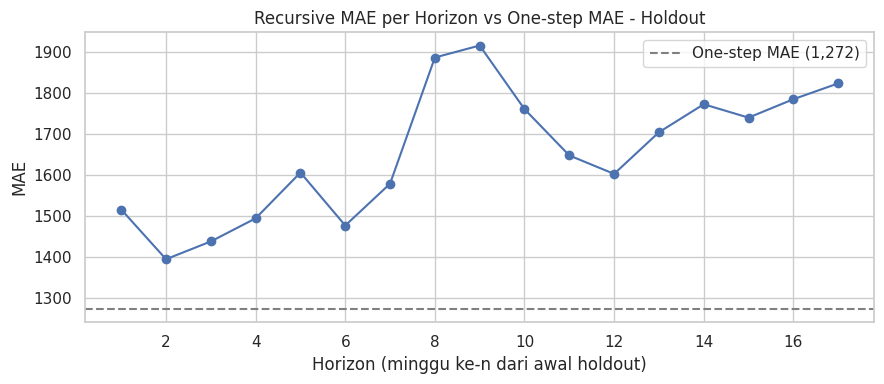

In [ ]:
horizon_mae = (
    holdout_recursive.groupby("Horizon")
    .apply(lambda g: mean_absolute_error(g["Actual"], g["Predicted_Recursive"]))
)

fig, ax = plt.subplots(figsize=(9, 4))
horizon_mae.plot(ax=ax, marker="o")
ax.axhline(onestep_mae, color="gray", linestyle="--", label=f"One-step MAE ({onestep_mae:,.0f})")
ax.set_xlabel("Horizon (minggu ke-n dari awal holdout)"); ax.set_ylabel("MAE")
ax.set_title("Recursive MAE per Horizon vs One-step MAE - Holdout")
ax.legend()
plt.tight_layout(); plt.show()

## 13. Forecast Analysis

In [ ]:
store_forecast = test_predictions.groupby("Store")["Predicted_Weekly_Sales"].agg(Total="sum", Average="mean").sort_values("Total", ascending=False)
dept_forecast = test_predictions.groupby("Dept")["Predicted_Weekly_Sales"].agg(Total="sum", Average="mean").sort_values("Total", ascending=False)

print("Top 5 Store (Total & Average forecast):")
print(store_forecast.head())
print("\nTop 5 Department (Total & Average forecast):")
print(dept_forecast.head())

Top 5 Store (Total & Average forecast):
            Total       Average
Store                          
4      92517456.0  33006.585938
20     88401280.0  31867.800781
13     85328304.0  30087.554688
2      80573936.0  28807.271484
10     79254280.0  28488.238281

Top 5 Department (Total & Average forecast):
            Total       Average
Dept                           
92    146926176.0  83718.617188
95    125454488.0  71484.039062
38    113212840.0  64508.742188
72     89665672.0  54740.949219
90     88137872.0  50221.007812


## 14. Model Interpretation

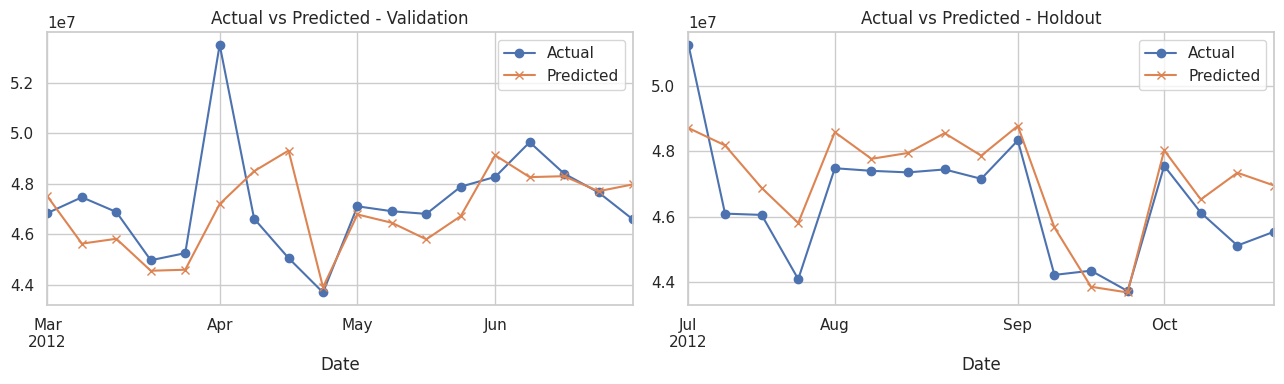

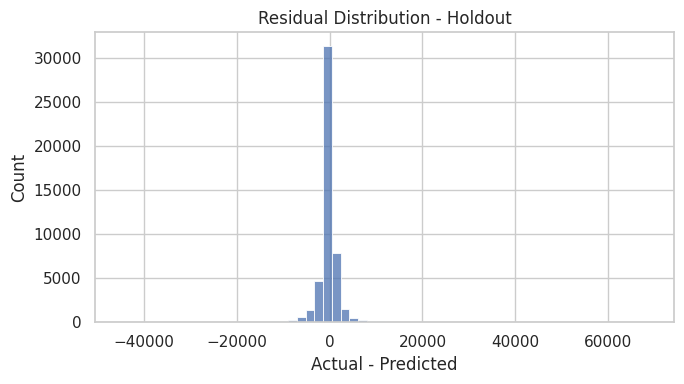

In [ ]:
val_pred = predict_with(best_model, X_val, Xt_val)
hold_pred = predict_with(best_model, X_hold, Xt_hold)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (label, dates, actual, pred) in zip(ax, [
    ("Validation", val_set["Date"], y_val, val_pred),
    ("Holdout", holdout_set["Date"], y_hold, hold_pred),
]):
    agg = pd.DataFrame({"Date": dates, "Actual": actual, "Predicted": pred}).groupby("Date")[["Actual", "Predicted"]].sum()
    agg["Actual"].plot(ax=a, label="Actual", marker="o")
    agg["Predicted"].plot(ax=a, label="Predicted", marker="x")
    a.set_title(f"Actual vs Predicted - {label}"); a.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(y_hold.values - hold_pred, bins=60, ax=ax)
ax.set_title("Residual Distribution - Holdout"); ax.set_xlabel("Actual - Predicted")
plt.tight_layout(); plt.show()

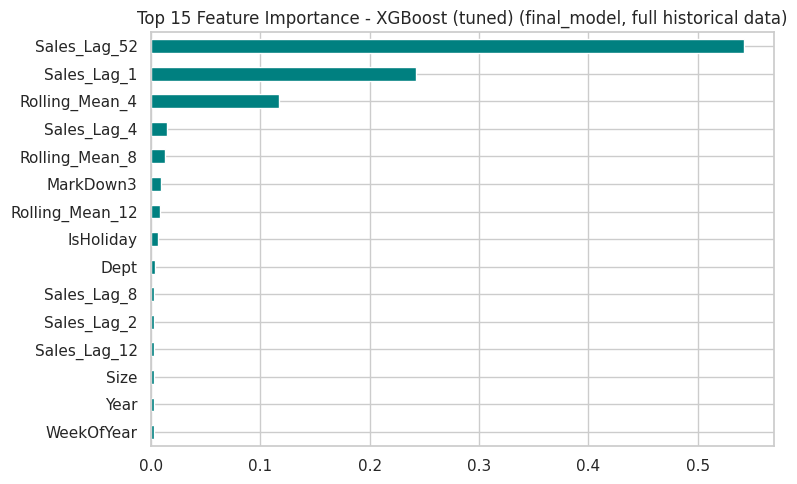

In [ ]:
if is_tree_model and hasattr(final_model, "feature_importances_"):
    importances = pd.Series(final_model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(8, 5))
    importances.head(15).sort_values().plot(kind="barh", ax=ax, color="teal")
    ax.set_title(f"Top 15 Feature Importance - {best_name} (final_model, full historical data)")
    plt.tight_layout(); plt.show()
else:
    print("Model terbaik adalah model linear - lihat koefisien, bukan feature_importances_.")

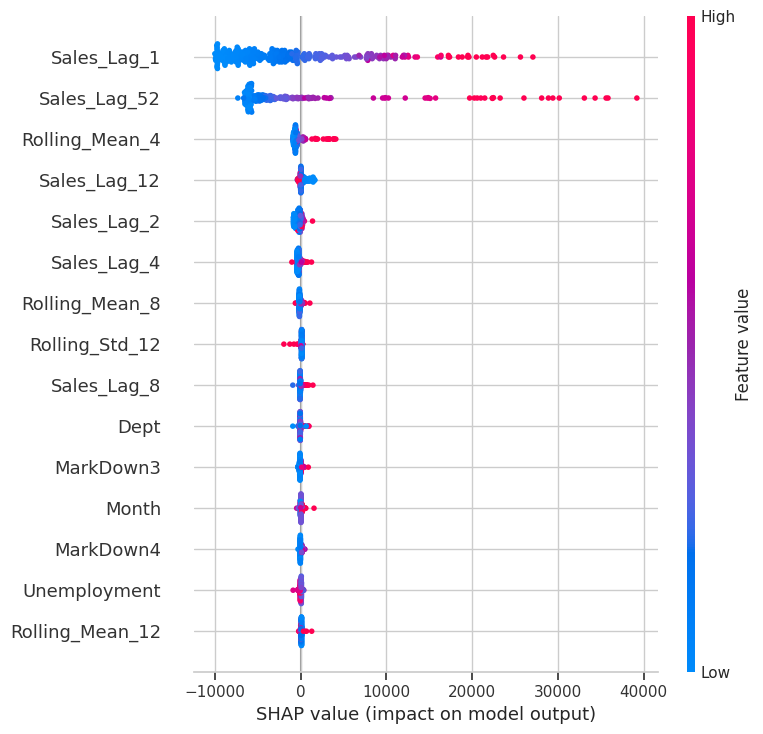

In [ ]:
if is_tree_model:
    import shap
    sample_X = Xt_hold.sample(min(300, len(Xt_hold)), random_state=RANDOM_STATE)
    explainer = shap.TreeExplainer(final_model)
    shap.summary_plot(explainer.shap_values(sample_X), sample_X, show=False, max_display=15)
    plt.tight_layout(); plt.show()

## 15. Business Insights

In [ ]:
best_hold_metrics = hold_table.loc[best_name]
top_store_hist = train_m.groupby("Store")["Weekly_Sales"].mean().idxmax()
top_dept_hist = train_m.groupby("Dept")["Weekly_Sales"].mean().idxmax()
backtest_horizon = int(holdout_recursive["Horizon"].max())

display(Markdown(
    f"- **Store**: Store {store_forecast.index[0]} punya total forecast tertinggi "
    f"({store_forecast.iloc[0]['Total']:,.0f}, rata-rata mingguan {store_forecast.iloc[0]['Average']:,.0f}); "
    f"secara historis Store {top_store_hist} yang rata-rata Weekly Sales-nya tertinggi.\n"
    f"- **Department**: Dept {dept_forecast.index[0]} punya total forecast tertinggi "
    f"({dept_forecast.iloc[0]['Total']:,.0f}, rata-rata mingguan {dept_forecast.iloc[0]['Average']:,.0f}); "
    f"secara historis Dept {top_dept_hist} yang rata-rata Weekly Sales-nya tertinggi.\n"
    f"- **Holiday effect**: rata-rata {lift:.1f}% lebih tinggi dibanding non-holiday week (asosiasi, bukan causal).\n"
    f"- **Model**: {best_name}, dipilih berdasarkan validation MAE, MAE holdout (blind) {best_hold_metrics['MAE']:,.1f}, "
    f"RMSE {best_hold_metrics['RMSE']:,.1f}, WAPE {best_hold_metrics['WAPE']*100:.1f}%, R2 {best_hold_metrics['R2']:.3f}.\n"
    f"- **Recursive backtest** ({backtest_horizon} minggu, holdout): MAE {recursive_mae:,.1f}, "
    f"{(recursive_mae/onestep_mae-1)*100:+.1f}% lebih tinggi dari one-step ({onestep_mae:,.1f}) - "
    f"error accumulation perlu jadi pertimbangan monitoring pada horizon lebih panjang."
))

- **Store**: Store 4 punya total forecast tertinggi (92,517,456, rata-rata mingguan 33,007); secara historis Store 20 yang rata-rata Weekly Sales-nya tertinggi.
- **Department**: Dept 92 punya total forecast tertinggi (146,926,176, rata-rata mingguan 83,719); secara historis Dept 92 yang rata-rata Weekly Sales-nya tertinggi.
- **Holiday effect**: rata-rata 7.1% lebih tinggi dibanding non-holiday week (asosiasi, bukan causal).
- **Model**: XGBoost (tuned), dipilih berdasarkan validation MAE, MAE holdout (blind) 1,272.1, RMSE 2,672.9, WAPE 8.0%, R2 0.985.
- **Recursive backtest** (17 minggu, holdout): MAE 1,655.4, +30.1% lebih tinggi dari one-step (1,272.1) - error accumulation perlu jadi pertimbangan monitoring pada horizon lebih panjang.

## 16. Business Recommendations

- **Inventory allocation:** prioritaskan stok tambahan untuk Store/Department dengan total forecast tertinggi, terutama menjelang minggu-minggu holiday.
- **Staffing:** sesuaikan jadwal staf dengan pola holiday lift yang terukur di Section 4 dan 15.
- **Promotional planning:** evaluasi ROI markdown per department sebelum diperluas, karena hubungan markdown-sales bersifat asosiatif, bukan causal.
- **Forecast monitoring:** bandingkan forecast mingguan dengan actual begitu tersedia; MAE/WAPE holdout pada Section 10 menjadi baseline untuk mendeteksi penurunan performa model dari waktu ke waktu.
- **Operationalization:** alur pembaruan forecast mingguan mengikuti `New Weekly Data -> Data Preparation -> Feature Engineering -> Model Prediction -> Forecast Monitoring -> Model Retraining`, dijalankan ulang setiap kali data aktual baru tersedia.

## 17. Executive Summary

In [ ]:
display(Markdown(
    f"Model **{best_name}** dipilih berdasarkan MAE terendah pada validation set "
    f"({val_table.loc[best_name, 'MAE']:,.1f}). Pada holdout evaluation (blind), model menghasilkan "
    f"MAE {best_hold_metrics['MAE']:,.1f}, RMSE {best_hold_metrics['RMSE']:,.1f}, "
    f"WAPE {best_hold_metrics['WAPE']*100:.1f}%, R2 {best_hold_metrics['R2']:.3f}. Recursive backtesting "
    f"{backtest_horizon} minggu di holdout menunjukkan MAE {(recursive_mae/onestep_mae-1)*100:+.1f}% lebih tinggi "
    f"dibanding one-step, sehingga forecast produksi ({test_predictions['Date'].nunique()} minggu) perlu "
    f"dipantau berkala ketika actual sales tersedia. Model final untuk forecasting produksi di-retrain ulang "
    f"di seluruh data historis (fit+val+holdout, {X_full.shape[0]:,} baris) dengan hyperparameter yang sama, "
    f"sesuai prinsip memanfaatkan seluruh informasi historis yang tersedia."
))

Model **XGBoost (tuned)** dipilih berdasarkan MAE terendah pada validation set (1,417.5). Pada holdout evaluation (blind), model menghasilkan MAE 1,272.1, RMSE 2,672.9, WAPE 8.0%, R2 0.985. Recursive backtesting 17 minggu di holdout menunjukkan MAE +30.1% lebih tinggi dibanding one-step, sehingga forecast produksi (39 minggu) perlu dipantau berkala ketika actual sales tersedia. Model final untuk forecasting produksi di-retrain ulang di seluruh data historis (fit+val+holdout, 261,083 baris) dengan hyperparameter yang sama, sesuai prinsip memanfaatkan seluruh informasi historis yang tersedia.